# 13 — Multi-view neural verification prototype

**Case:** `CASE_001`  
**Purpose:** research-only verification of report-listed traumatic findings using the original patient CT, two independent pretrained neural branches, and a geometric midline measurement.

This notebook does **not** make a diagnosis. It does not treat the report as voxel-level ground truth. It produces candidate slice ranges and review scores for expert inspection.

Pipeline:

1. Original brain-kernel CT → published RSNA-trained CNN–LSTM → axial hemorrhage-subtype scores.
2. Original bone-kernel CT → published YOLOv8 depressed-skull-fracture detector → fracture-candidate boxes.
3. Original CT + brain mask → geometric ventricular/CSF-candidate midpoint estimate → exploratory midline displacement.
4. Model-guided native-HU maps → axial, coronal, and sagittal review ranges and images.
5. Report-level comparison only; no report row is used to train, calibrate, or spatially supervise a model.

Primary references: [RSNA ICH challenge](https://www.rsna.org/artificial-intelligence/ai-image-challenge/RSNA-Intracranial-Hemorrhage-Detection-Challenge-2019), [VinBigData CNN–LSTM](https://github.com/vinbigdata-medical/midl2020-cnnlstm-ich), [public skull-fracture detector](https://github.com/radiomicsaicmu/YOLO-for-skull-fracture-detection), and [temperature scaling](https://arxiv.org/abs/1706.04599).

## 1. Safety, scope, and score semantics

- The CT voxels are the primary evidence. The neural models are secondary research tools.
- The hemorrhage checkpoint predicts **image-level/slice-level classes**, not voxel masks.
- The fracture checkpoint was trained for **depressed skull fractures**; it is not a general sphenoid/occipital fracture rule-out model.
- Model confidence is not the same as clinical probability.
- No independent labeled validation set from this scanner is available. Therefore the notebook reports raw probabilities, a fixed temperature-scaling sensitivity view, TTA variability, and a conservative lower score. It does **not** claim local empirical calibration.
- The report is compared after inference. It is not used as training data or ground truth.

In [1]:
from pathlib import Path
from collections import OrderedDict
import json, math, platform, warnings

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import ndimage as ndi
from scipy.special import expit
from skimage.measure import label, regionprops

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet50

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"figure.dpi": 125, "savefig.dpi": 180})

PROJECT_ROOT = Path(r"F:\csstdy")
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "13_multiview_neural_verification"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
MODEL_DIR = OUTPUT_DIR / "models"
for p in (OUTPUT_DIR, FIGURE_DIR, TABLE_DIR, MODEL_DIR):
    p.mkdir(parents=True, exist_ok=True)

BRAIN_CT_PATH = PROJECT_ROOT / "outputs/09_totalsegmentator_dl_skull_brain/input/CASE_001_brain_kernel_ct.nii.gz"
BONE_CT_PATH = PROJECT_ROOT / "outputs/10_totalsegmentator_sharp_skull/input/CASE_001_bone_kernel_ct.nii.gz"
BRAIN_MASK_PATH = PROJECT_ROOT / "outputs/09_totalsegmentator_dl_skull_brain/segmentations/brain.nii.gz"
SKULL_MASK_PATH = PROJECT_ROOT / "outputs/10_totalsegmentator_sharp_skull/craniofacial_segmentations/skull.nii.gz"
REPORT_PATH = PROJECT_ROOT / "Single_Patient_Study/Single_Patient_Study/CASE_001/REPORT/CASE_001_structured_annotations.csv"
ICH_WEIGHTS = MODEL_DIR / "ich_cnn_lstm_resnet50.pth"
FRACTURE_WEIGHTS = MODEL_DIR / "skull_fracture_yolov8_best.pt"

required = [BRAIN_CT_PATH, BONE_CT_PATH, BRAIN_MASK_PATH, SKULL_MASK_PATH, ICH_WEIGHTS, FRACTURE_WEIGHTS]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError("Missing required files:\n" + "\n".join(missing))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)
print("Output:", OUTPUT_DIR)

Device: cuda
PyTorch: 2.14.0+cu130
Output: F:\csstdy\outputs\13_multiview_neural_verification


## 2. Load original CT volumes, masks, and report-level annotations

In [2]:
brain_img = nib.load(BRAIN_CT_PATH)
bone_img = nib.load(BONE_CT_PATH)
brain_mask_img = nib.load(BRAIN_MASK_PATH)
skull_mask_img = nib.load(SKULL_MASK_PATH)

brain_ct = brain_img.get_fdata(dtype=np.float32).copy()
bone_ct = bone_img.get_fdata(dtype=np.float32).copy()
brain_mask = brain_mask_img.get_fdata(dtype=np.float32) > 0.5
skull_mask = skull_mask_img.get_fdata(dtype=np.float32) > 0.5

assert brain_ct.shape == bone_ct.shape == brain_mask.shape == skull_mask.shape
affine = brain_img.affine.copy()
spacing = np.asarray(brain_img.header.get_zooms()[:3], dtype=float)
axcodes = nib.aff2axcodes(affine)

report_df = pd.read_csv(REPORT_PATH) if REPORT_PATH.exists() else pd.DataFrame(
    columns=["finding", "report_status", "region", "reconstruction", "certainty"]
)

print("Shape:", brain_ct.shape)
print("Voxel spacing (mm):", spacing)
print("Orientation codes:", axcodes)
display(report_df)

Shape: (512, 512, 227)
Voxel spacing (mm): [0.55574608 0.55574608 0.75      ]
Orientation codes: ('L', 'A', 'S')


,finding,report_status,region,reconstruction,certainty
0,Hemorrhagic contusion,Reported,Left frontal and temporal lobes,BRAIN_HR36F,Explicitly reported
1,Acute subdural hematoma (SDH),Reported,Left fronto-temporo-parietal region,BRAIN_HR36F,Explicitly reported
2,Posterior interhemispheric SDH,Reported,Posterior interhemispheric region,BRAIN_HR36F,Explicitly reported
3,Intraventricular hemorrhage (IVH),Likely,Bilateral lateral ventricular occipital horns,BRAIN_HR36F,Reported as likely
4,Subarachnoid hemorrhage (SAH),Likely,Left frontoparietal lobes,BRAIN_HR36F,Reported as likely
5,Mass effect / midline shift,Reported,Midline; approximately 3 mm shift to the right,BRAIN_HR36F,Explicitly reported
6,Postoperative extra-axial collection,Reported,Extra-axial postoperative region,BRAIN_HR36F,Explicitly reported
7,Right sphenoid bone fracture,Suspected,Right sphenoid bone,BONE_HR60F,Reported as suspected
8,Right occipital bone fracture,Suspected,Right occipital bone,BONE_HR60F,Reported as suspected


## 3. Pretrained hemorrhage branch

The published checkpoint is a ResNet-50 slice encoder followed by a two-layer bidirectional LSTM. Its six outputs are `any`, `intraparenchymal`, `intraventricular`, `subarachnoid`, `subdural`, and `epidural`.

The published preprocessing forms one RGB-like image from three channels: brain window (level 40, width 80), subdural window (75, 215), and bone window (600, 2800), followed by ImageNet normalization. This implementation reproduces that convention directly from the native NIfTI HU values. Because this scan has 0.75-mm slices while the external training distribution was much thicker, approximately 5-mm-spaced axial samples are passed to the sequence model and then interpolated back onto native slice indices.

In [3]:
ICH_CLASSES = ["any", "intraparenchymal", "intraventricular", "subarachnoid", "subdural", "epidural"]
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class RecurrentDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.recurrent = nn.LSTM(
            input_size=2048, hidden_size=512, num_layers=2,
            bidirectional=True, batch_first=True, dropout=0.0
        )
        self.fc = nn.Linear(1024, 6)

class CNNLSTMICH(nn.Module):
    def __init__(self):
        super().__init__()
        backbone = resnet50(weights=None)
        self.layer0 = nn.Sequential(OrderedDict([
            ("conv1", backbone.conv1), ("bn1", backbone.bn1),
            ("relu", backbone.relu), ("maxpool", backbone.maxpool),
        ]))
        self.layer1, self.layer2 = backbone.layer1, backbone.layer2
        self.layer3, self.layer4 = backbone.layer3, backbone.layer4
        self.decoder = RecurrentDecoder()

    def encode(self, x):
        x = self.layer0(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        return F.adaptive_avg_pool2d(x, 1).flatten(1)

    def decode(self, features):
        x, _ = self.decoder.recurrent(features)
        return self.decoder.fc(x)

def hu_window(volume2d, center=40.0, width=80.0):
    lo, hi = center - width / 2.0, center + width / 2.0
    return np.clip((volume2d - lo) / (hi - lo), 0.0, 1.0)

BASE_WINDOWS = ((40.0, 80.0), (75.0, 215.0), (600.0, 2800.0))

def make_ich_tensor(z_indices, windows=BASE_WINDOWS, flip_lr=False):
    out = []
    for z in z_indices:
        channels = [hu_window(brain_ct[:, :, int(z)], c, w) for c, w in windows]
        if flip_lr:
            channels = [np.flip(ch, axis=0).copy() for ch in channels]
        rgb = np.stack(channels, axis=0).astype(np.float32)
        t = torch.from_numpy(rgb)
        out.append((t - IMAGENET_MEAN) / IMAGENET_STD)
    return torch.stack(out)

ich_model = CNNLSTMICH()
checkpoint = torch.load(ICH_WEIGHTS, map_location="cpu", weights_only=False)
load_result = ich_model.load_state_dict(checkpoint["state_dict"], strict=True)
ich_model.to(DEVICE).eval()
print(load_result)
print("Checkpoint epoch:", checkpoint.get("epoch"), "best metric:", checkpoint.get("best_metric"))

<All keys matched successfully>
Checkpoint epoch: 30 best metric: tensor(0.0637)


In [4]:
brain_z = np.where(brain_mask.any(axis=(0, 1)))[0]
z_first, z_last = int(brain_z.min()), int(brain_z.max())
model_stride = max(1, int(round(5.0 / spacing[2])))
model_z = np.arange(z_first, z_last + 1, model_stride, dtype=int)
if model_z[-1] != z_last:
    model_z = np.r_[model_z, z_last]

def infer_ich_sequence(windows=BASE_WINDOWS, flip_lr=False, batch_size=8):
    features = []
    with torch.inference_mode():
        for start in range(0, len(model_z), batch_size):
            z_batch = model_z[start:start + batch_size]
            x = make_ich_tensor(z_batch, windows, flip_lr).to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
                f = ich_model.encode(x)
            features.append(f.float().cpu())
        feat = torch.cat(features, dim=0).unsqueeze(0).to(DEVICE)
        logits = ich_model.decode(feat).squeeze(0).float().cpu().numpy()
    return logits

# Fixed, pre-declared test-time views. Their spread is an uncertainty indicator,
# not a substitute for external calibration.
tta_specs = [
    (BASE_WINDOWS, False, "published_three_window_input"),
    (((35.0, 70.0), (70.0, 200.0), (550.0, 2600.0)), False, "narrower_window_sensitivity"),
    (((45.0, 90.0), (80.0, 230.0), (650.0, 3000.0)), False, "wider_window_sensitivity"),
    (BASE_WINDOWS, True,  "published_input_lr_flip"),
]
tta_logits = []
for windows, flip, name in tta_specs:
    print("Running", name)
    tta_logits.append(infer_ich_sequence(windows, flip))
tta_logits = np.stack(tta_logits, axis=0)
tta_prob = expit(tta_logits)

mean_prob_sampled = tta_prob.mean(axis=0)
sd_prob_sampled = tta_prob.std(axis=0, ddof=1)
temperature = 1.5  # fixed sensitivity view; NOT fitted on this patient/report
temp_prob_sampled = expit(tta_logits.mean(axis=0) / temperature)

native_z = np.arange(brain_ct.shape[2])
mean_prob = np.column_stack([
    np.interp(native_z, model_z, mean_prob_sampled[:, j], left=0, right=0)
    for j in range(len(ICH_CLASSES))
])
sd_prob = np.column_stack([
    np.interp(native_z, model_z, sd_prob_sampled[:, j], left=0, right=0)
    for j in range(len(ICH_CLASSES))
])
temp_prob = np.column_stack([
    np.interp(native_z, model_z, temp_prob_sampled[:, j], left=0, right=0)
    for j in range(len(ICH_CLASSES))
])
lower_review = np.clip(mean_prob - 1.96 * sd_prob, 0, 1)

slice_scores = pd.DataFrame({"axial_slice": native_z})
for j, cls in enumerate(ICH_CLASSES):
    slice_scores[f"{cls}_raw_mean"] = mean_prob[:, j]
    slice_scores[f"{cls}_tta_sd"] = sd_prob[:, j]
    slice_scores[f"{cls}_temperature_T1.5"] = temp_prob[:, j]
    slice_scores[f"{cls}_lower95_review"] = lower_review[:, j]
slice_scores.to_csv(TABLE_DIR / "hemorrhage_slice_scores.csv", index=False)
print(f"Neural inference complete on {len(model_z)} sampled slices; mapped to {len(native_z)} native slices.")

Running published_three_window_input


Running narrower_window_sensitivity


Running wider_window_sensitivity


Running published_input_lr_flip


Neural inference complete on 27 sampled slices; mapped to 227 native slices.


## 4. Confidence, uncertainty, and axial candidate ranges

The fixed temperature `T=1.5` only shows how confidence changes under conservative logit shrinkage. It was **not fitted** to this patient or report and must not be called locally calibrated. The TTA standard deviation shows stability across predeclared window/flip views. The lower review score is `mean − 1.96 × TTA SD`, clipped to [0,1].

Candidate ranges use a fixed 0.50 threshold. If a class never reaches 0.50, the notebook reports a peak-centred review range at half its peak, explicitly marked as below-threshold.

In [5]:
def longest_true_runs(mask):
    runs, start = [], None
    for i, flag in enumerate(np.r_[mask, False]):
        if flag and start is None:
            start = i
        elif not flag and start is not None:
            runs.append((start, i - 1))
            start = None
    return runs

range_rows = []
for cls in ["intraparenchymal", "intraventricular", "subarachnoid", "subdural"]:
    j = ICH_CLASSES.index(cls)
    p = mean_prob[:, j]
    above = (p >= 0.50) & np.isin(native_z, brain_z)
    status = "fixed_threshold_0.50"
    if not above.any():
        peak = float(p.max())
        above = (p >= max(0.05, peak * 0.50)) & np.isin(native_z, brain_z)
        status = "peak_review_range_below_0.50"
    runs = longest_true_runs(above)
    if not runs:
        runs = [(int(np.argmax(p)), int(np.argmax(p)))]
        status = "peak_slice_only"
    for a, b in runs:
        range_rows.append({
            "finding_class": cls, "axis": "axial", "start_slice": a, "end_slice": b,
            "peak_slice": int(a + np.argmax(p[a:b+1])), "peak_raw_probability": float(p[a:b+1].max()),
            "peak_tta_sd": float(sd_prob[a:b+1, j].max()), "selection_status": status,
            "calibration_status": "not locally calibrated",
        })
range_df = pd.DataFrame(range_rows)
range_df.to_csv(TABLE_DIR / "hemorrhage_axial_ranges.csv", index=False)

summary_rows = []
for cls in ICH_CLASSES:
    j = ICH_CLASSES.index(cls)
    z = int(np.argmax(mean_prob[:, j]))
    summary_rows.append({
        "class": cls, "peak_native_slice": z,
        "peak_raw_mean": float(mean_prob[z, j]),
        "peak_temperature_T1.5": float(temp_prob[z, j]),
        "TTA_SD_at_peak": float(sd_prob[z, j]),
        "lower95_review_at_peak": float(lower_review[z, j]),
        "score_interpretation": "research model score; not a clinical probability",
    })
ich_summary = pd.DataFrame(summary_rows)
ich_summary.to_csv(TABLE_DIR / "hemorrhage_peak_scores.csv", index=False)
display(ich_summary.round(4))
display(range_df.round(4))

,class,peak_native_slice,peak_raw_mean,peak_temperature_T1.5,TTA_SD_at_peak,lower95_review_at_peak,score_interpretation
0,any,95,0.2270,0.2844,0.1804,0.0000,research model score; not a clinical probability
1,intraparenchymal,95,0.0103,0.0308,0.0144,0.0000,research model score; not a clinical probability
2,intraventricular,95,0.0079,0.0340,0.0063,0.0000,research model score; not a clinical probability
3,subarachnoid,202,0.0136,0.0541,0.0018,0.0102,research model score; not a clinical probability
4,subdural,109,0.2332,0.3059,0.0871,0.0625,research model score; not a clinical probability
5,epidural,123,0.0083,0.0384,0.0031,0.0023,research model score; not a clinical probability


,finding_class,axis,start_slice,end_slice,peak_slice,peak_raw_probability,peak_tta_sd,selection_status,calibration_status
0,intraparenchymal,axial,95,95,95,0.0103,0.0144,peak_slice_only,not locally calibrated
1,intraventricular,axial,95,95,95,0.0079,0.0063,peak_slice_only,not locally calibrated
2,subarachnoid,axial,202,202,202,0.0136,0.0018,peak_slice_only,not locally calibrated
3,subdural,axial,48,192,109,0.2332,0.1113,peak_review_range_below_0.50,not locally calibrated
4,subdural,axial,201,202,202,0.1300,0.0293,peak_review_range_below_0.50,not locally calibrated


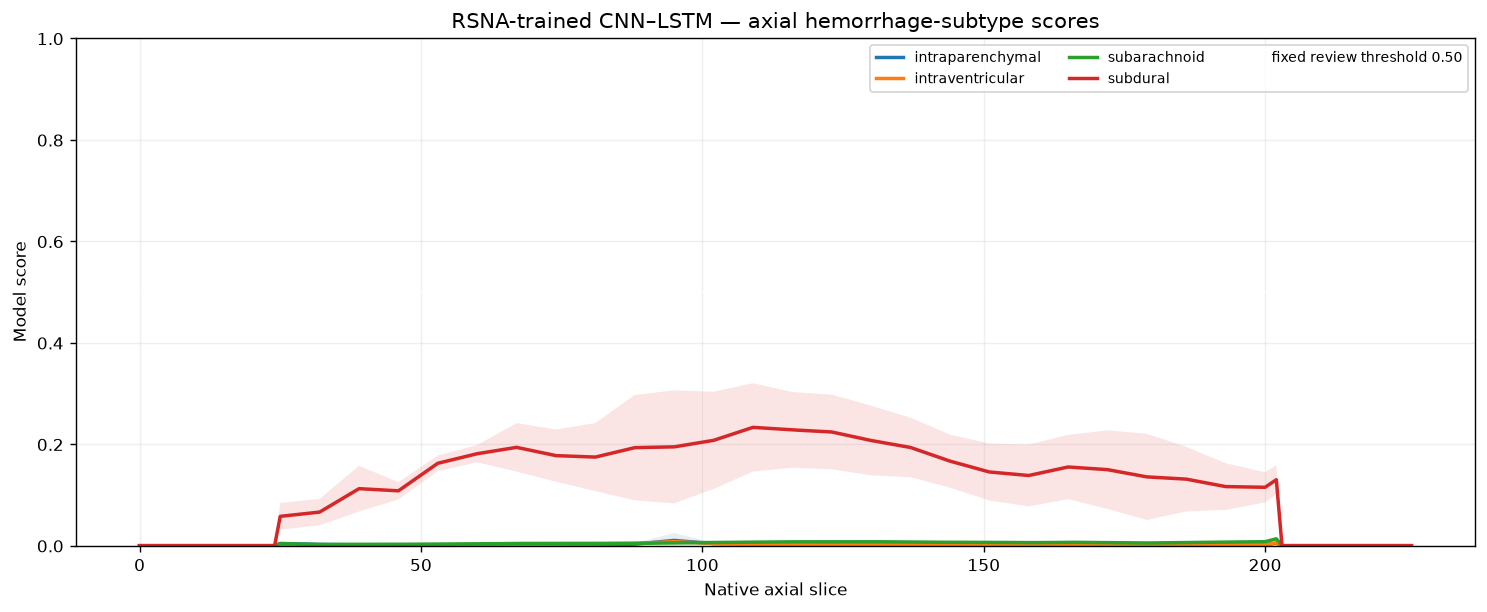

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
for cls in ["intraparenchymal", "intraventricular", "subarachnoid", "subdural"]:
    j = ICH_CLASSES.index(cls)
    ax.plot(native_z, mean_prob[:, j], lw=2, label=cls)
    ax.fill_between(native_z, np.clip(mean_prob[:, j]-sd_prob[:, j], 0, 1),
                    np.clip(mean_prob[:, j]+sd_prob[:, j], 0, 1), alpha=.12)
ax.axhline(.5, color="white", ls="--", lw=1, alpha=.65, label="fixed review threshold 0.50")
ax.set(xlabel="Native axial slice", ylabel="Model score", ylim=(0, 1),
       title="RSNA-trained CNN–LSTM — axial hemorrhage-subtype scores")
ax.legend(ncol=3, fontsize=8)
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "hemorrhage_axial_score_curves.png", bbox_inches="tight")
plt.show()

## 5. Hybrid multi-view localization from original CT

The CNN–LSTM is a slice classifier, not a segmentation network. To avoid pretending it creates voxel masks, spatial review maps are constructed transparently:

`model-guided review map = axial neural score × native-CT HU candidate weighting × anatomical weighting`

The original CT supplies all voxel intensities. The neural score only prioritizes axial levels. These maps are exploratory image-characterization aids, not lesion segmentations.

In [7]:
inner = ndi.binary_erosion(brain_mask, iterations=3)
inside_dist = ndi.distance_transform_edt(brain_mask, sampling=spacing)
boundary_band = brain_mask & (inside_dist <= 12.0)
central = brain_mask & (inside_dist >= 8.0)

def soft_band(x, lo, hi, softness=5.0):
    return expit((x-lo)/softness) * expit((hi-x)/softness)

native_weights = {
    "intraparenchymal": soft_band(brain_ct, 38, 100, 6) * inner,
    "intraventricular": soft_band(brain_ct, 32, 100, 7) * central,
    "subarachnoid": soft_band(brain_ct, 35, 95, 6) * boundary_band,
    "subdural": soft_band(brain_ct, 35, 110, 7) * boundary_band,
}

review_maps = {}
multiview_rows = []
for cls, native_w in native_weights.items():
    j = ICH_CLASSES.index(cls)
    m = native_w * mean_prob[:, j][None, None, :]
    review_maps[cls] = m.astype(np.float32)
    positive = m[m > 0]
    threshold = float(np.percentile(positive, 99.0)) if positive.size else np.inf
    candidate = m >= threshold
    coords = np.argwhere(candidate)
    if coords.size:
        for axis, name in enumerate(["sagittal/LR voxel axis", "coronal/AP voxel axis", "axial/SI voxel axis"]):
            values = coords[:, axis]
            multiview_rows.append({
                "finding_class": cls, "plane_range": name,
                "start_slice": int(values.min()), "end_slice": int(values.max()),
                "peak_slice": int(np.unravel_index(np.argmax(m), m.shape)[axis]),
                "map_definition": "neural axial score x native-HU/anatomical weighting",
            })

multiview_df = pd.DataFrame(multiview_rows)
multiview_df.to_csv(TABLE_DIR / "hemorrhage_multiview_review_ranges.csv", index=False)
display(multiview_df)

,finding_class,plane_range,start_slice,end_slice,peak_slice,map_definition
0,intraparenchymal,sagittal/LR voxel axis,119,329,183,neural axial score x native-HU/anatomical weig...
1,intraparenchymal,coronal/AP voxel axis,138,389,357,neural axial score x native-HU/anatomical weig...
2,intraparenchymal,axial/SI voxel axis,92,99,95,neural axial score x native-HU/anatomical weig...
3,intraventricular,sagittal/LR voxel axis,131,314,183,neural axial score x native-HU/anatomical weig...
4,intraventricular,coronal/AP voxel axis,150,376,358,neural axial score x native-HU/anatomical weig...
5,intraventricular,axial/SI voxel axis,92,98,95,neural axial score x native-HU/anatomical weig...
6,subarachnoid,sagittal/LR voxel axis,113,343,223,neural axial score x native-HU/anatomical weig...
7,subarachnoid,coronal/AP voxel axis,139,400,251,neural axial score x native-HU/anatomical weig...
8,subarachnoid,axial/SI voxel axis,113,202,202,neural axial score x native-HU/anatomical weig...
9,subdural,sagittal/LR voxel axis,116,340,250,neural axial score x native-HU/anatomical weig...


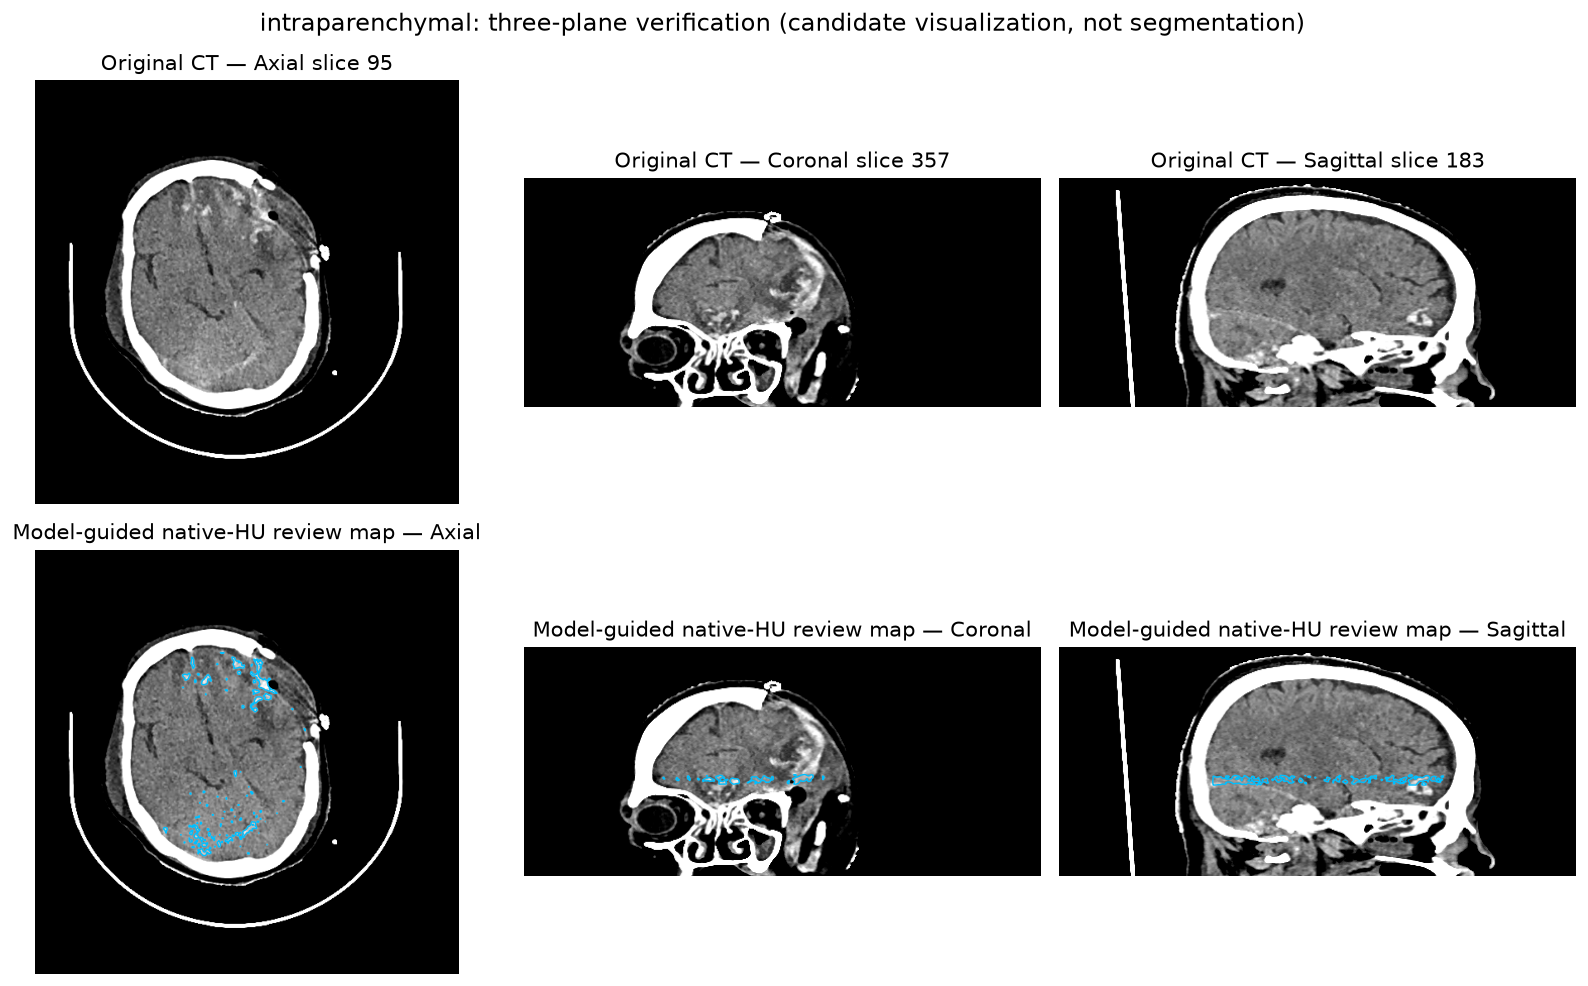

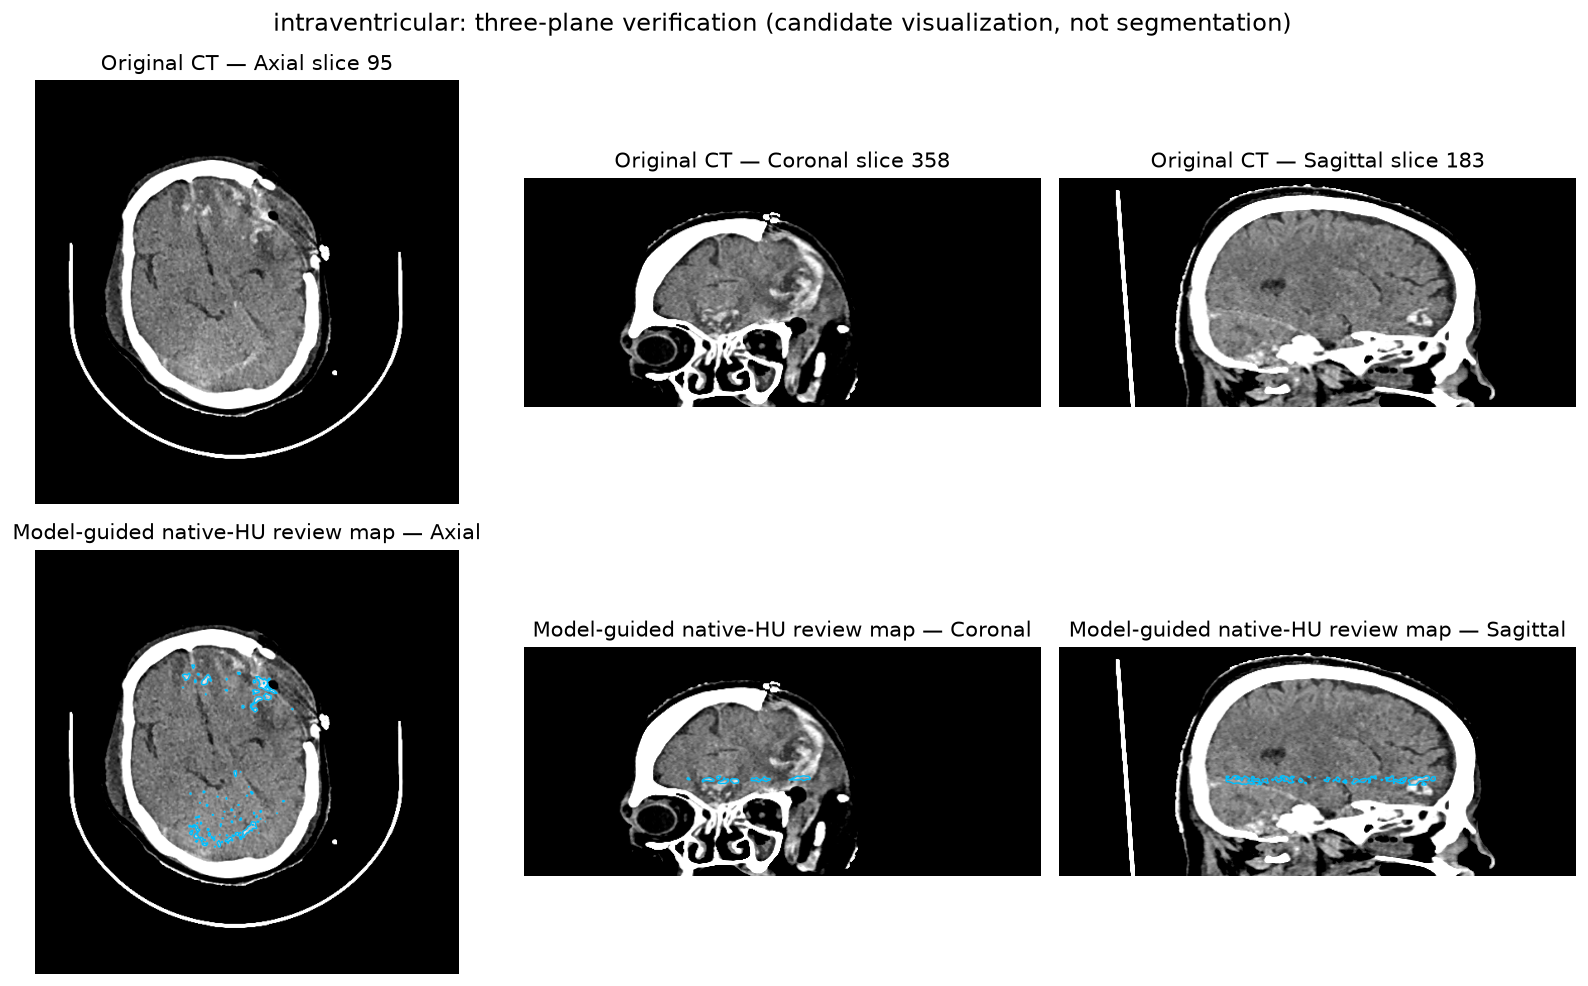

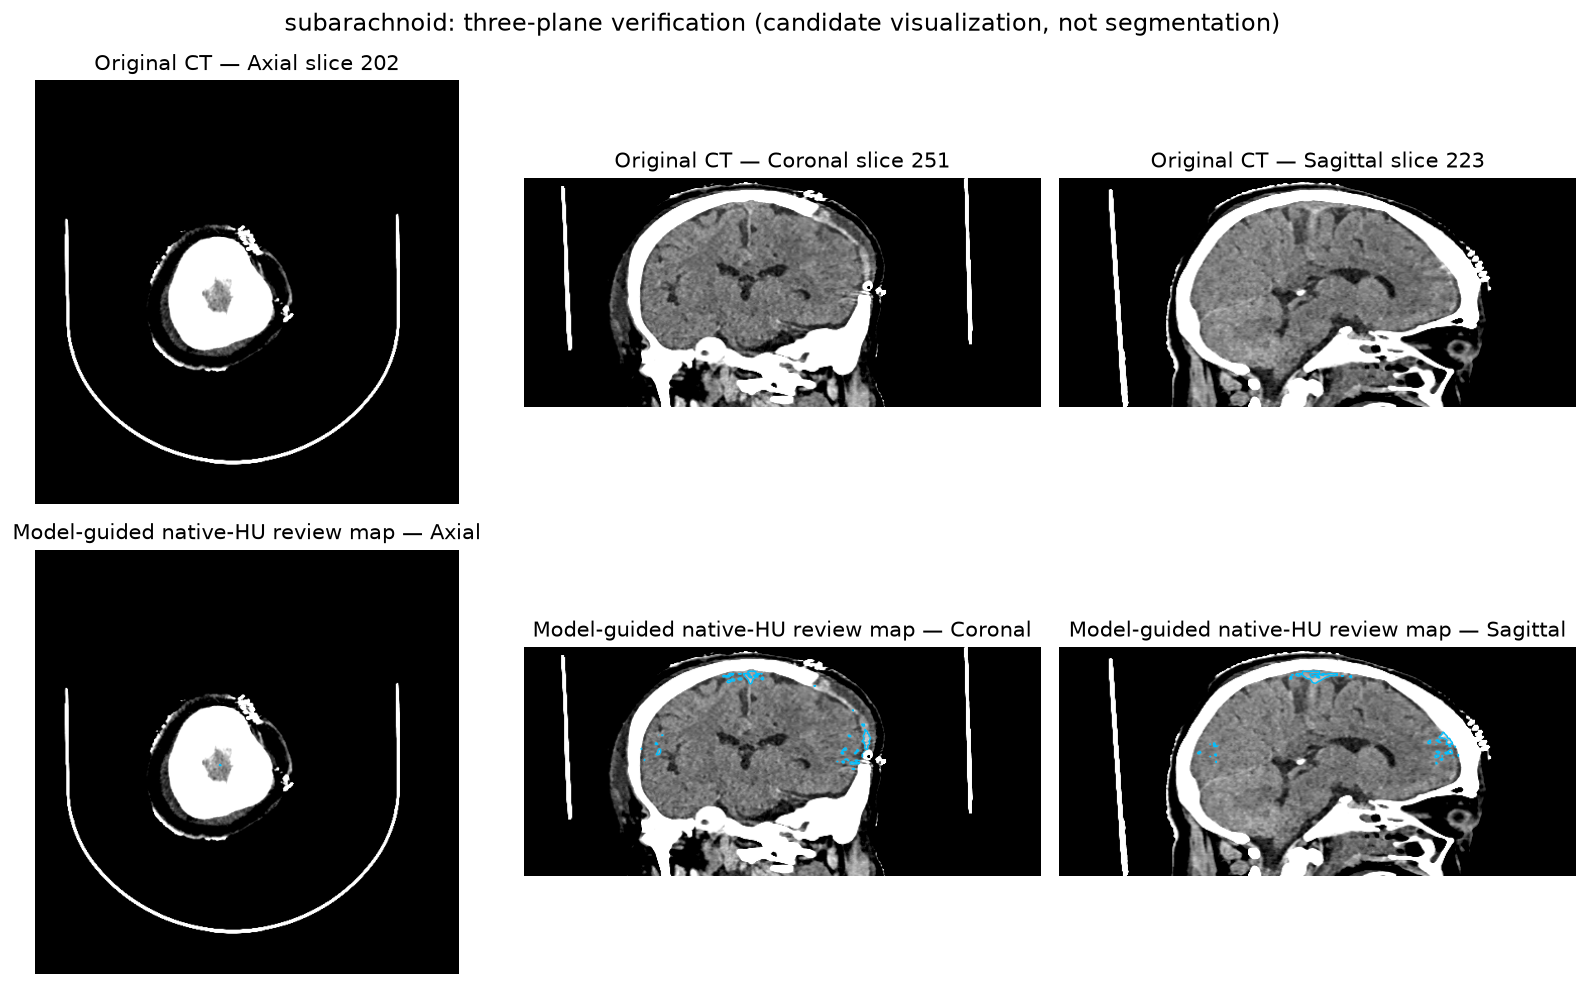

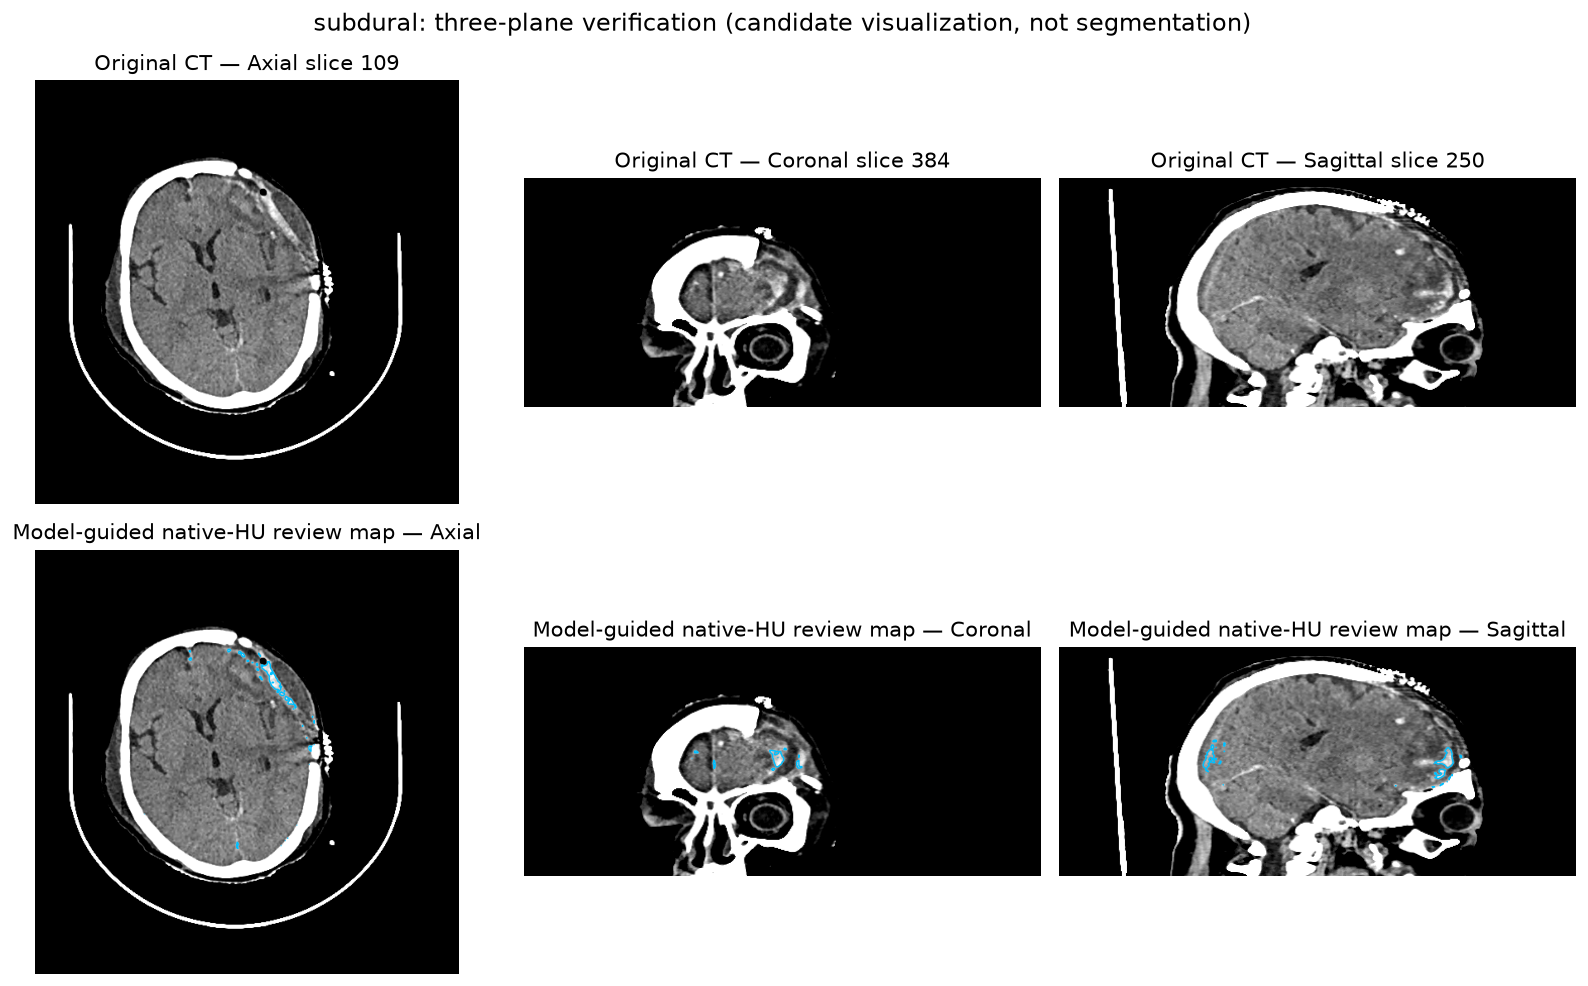

In [8]:
def oriented_slice(volume, axis, index):
    arr = np.take(volume, int(index), axis=axis)
    return np.rot90(arr)

def class_multiplanar_figure(cls):
    m = review_maps[cls]
    peak = np.unravel_index(np.argmax(m), m.shape)
    fig, axes = plt.subplots(2, 3, figsize=(13, 8))
    plane_specs = [(2, peak[2], "Axial"), (1, peak[1], "Coronal"), (0, peak[0], "Sagittal")]
    for col, (axis, idx, name) in enumerate(plane_specs):
        ct2 = oriented_slice(brain_ct, axis, idx)
        map2 = oriented_slice(m, axis, idx)
        axes[0, col].imshow(ct2, cmap="gray", vmin=0, vmax=80)
        axes[0, col].set_title(f"Original CT — {name} slice {idx}")
        axes[1, col].imshow(ct2, cmap="gray", vmin=0, vmax=80)
        if np.nanmax(map2) > 0:
            levels = [np.nanpercentile(map2[map2 > 0], 97)]
            axes[1, col].contour(map2, levels=levels, colors="deepskyblue", linewidths=.8)
        axes[1, col].set_title(f"Model-guided native-HU review map — {name}")
        for row in range(2): axes[row, col].axis("off")
    fig.suptitle(f"{cls}: three-plane verification (candidate visualization, not segmentation)", fontsize=14)
    fig.tight_layout()
    out = FIGURE_DIR / f"{cls}_multiplanar_verification.png"
    fig.savefig(out, bbox_inches="tight")
    plt.show()
    return out

hemorrhage_figures = [class_multiplanar_figure(c) for c in native_weights]

## 6. Separate pretrained skull-fracture branch

This is a published YOLOv8 detector trained for **depressed skull fractures**. It uses the original bone-kernel CT after a fixed bone window (level 600 HU, width 2800 HU). Its bounding-box confidence is exported as raw model confidence. Because there is no local labeled calibration cohort, the number is not a calibrated clinical probability.

The report mentions suspected right sphenoid and right occipital fractures. Those may not match the detector's narrower depressed-fracture training target; a negative detector result cannot exclude either report-level finding.

In [9]:
from ultralytics import YOLO

fracture_model = YOLO(str(FRACTURE_WEIGHTS))
print("Detector classes:", fracture_model.names)

def bone_window_uint8(slice_hu, center=600.0, width=2800.0):
    lo, hi = center - width/2, center + width/2
    x = np.clip((slice_hu-lo)/(hi-lo), 0, 1)
    return np.round(255*x).astype(np.uint8)

bone_z = np.where(skull_mask.any(axis=(0, 1)))[0]
bone_images = []
for z in bone_z:
    g = bone_window_uint8(bone_ct[:, :, int(z)])
    bone_images.append(np.repeat(g[..., None], 3, axis=2))

fracture_results = fracture_model.predict(
    source=bone_images, imgsz=512, conf=0.05, iou=0.45,
    device=0 if DEVICE.type == "cuda" else "cpu", batch=8,
    max_det=20, verbose=False
)

fracture_rows = []
for z, result in zip(bone_z, fracture_results):
    if result.boxes is None:
        continue
    for box in result.boxes:
        xyxy = box.xyxy.detach().cpu().numpy().reshape(-1)
        conf = float(box.conf.detach().cpu().item())
        x1i, y1i = max(0, int(np.floor(xyxy[0]))), max(0, int(np.floor(xyxy[1])))
        x2i, y2i = min(skull_mask.shape[1], int(np.ceil(xyxy[2]))), min(skull_mask.shape[0], int(np.ceil(xyxy[3])))
        roi_hu = bone_ct[y1i:y2i, x1i:x2i, int(z)]
        skull2d_near = ndi.binary_dilation(skull_mask[:, :, int(z)], iterations=6)
        roi_near = skull2d_near[y1i:y2i, x1i:x2i]
        near_skull_fraction = float(roi_near.mean()) if roi_near.size else 0.0
        very_dense_fraction = float((roi_hu >= 2500).mean()) if roi_hu.size else 0.0
        if near_skull_fraction < 0.05:
            qa_flag = "off-skull / likely model false-positive candidate"
        elif very_dense_fraction > 0.05:
            qa_flag = "hyperdense-material confounder candidate"
        else:
            qa_flag = "on/near-skull review candidate"
        fracture_rows.append({
            "axial_slice": int(z), "confidence_raw": conf,
            "x1": float(xyxy[0]), "y1": float(xyxy[1]),
            "x2": float(xyxy[2]), "y2": float(xyxy[3]),
            "detector_scope": "depressed skull fracture",
            "calibration_status": "not locally calibrated",
            "near_skull_fraction": near_skull_fraction,
            "very_dense_fraction_ge_2500HU": very_dense_fraction,
            "ct_quality_flag": qa_flag,
        })

fracture_df = pd.DataFrame(fracture_rows)
if fracture_df.empty:
    fracture_df = pd.DataFrame(columns=["axial_slice","confidence_raw","x1","y1","x2","y2","detector_scope","calibration_status"])
else:
    fracture_df = fracture_df.sort_values("confidence_raw", ascending=False).reset_index(drop=True)
fracture_df.to_csv(TABLE_DIR / "skull_fracture_candidates.csv", index=False)
display(fracture_df.head(20).round(4))
print("Candidate boxes at confidence >= 0.05:", len(fracture_df))

# Cluster neighbouring boxes so repeated detections through adjacent slices are
# summarized as one 3-D review candidate. Spread across slices is an uncertainty/
# stability indicator, not a calibrated confidence interval.
clusters = []
if len(fracture_df):
    ordered = fracture_df.sort_values("axial_slice").copy()
    ordered["cx"] = (ordered.x1 + ordered.x2) / 2
    ordered["cy"] = (ordered.y1 + ordered.y2) / 2
    assignment = {}
    for idx, row in ordered.iterrows():
        choices = []
        for cid, c in enumerate(clusters):
            dz = int(row.axial_slice) - c["last_z"]
            dist = float(np.hypot(row.cx-c["last_cx"], row.cy-c["last_cy"]))
            if 0 <= dz <= 5 and dist <= 55:
                choices.append((dist + 5*dz, cid))
        if choices:
            cid = min(choices)[1]
        else:
            cid = len(clusters)
            clusters.append({"indices": [], "last_z": int(row.axial_slice),
                             "last_cx": float(row.cx), "last_cy": float(row.cy)})
        clusters[cid]["indices"].append(idx)
        clusters[cid].update(last_z=int(row.axial_slice), last_cx=float(row.cx), last_cy=float(row.cy))
        assignment[idx] = cid + 1
    fracture_df["cluster_id"] = fracture_df.index.map(assignment)

cluster_rows = []
brain_world = nib.affines.apply_affine(affine, np.argwhere(brain_mask))
world_mid_x = float((brain_world[:,0].min() + brain_world[:,0].max()) / 2)
for cid, c in enumerate(clusters, start=1):
    g = fracture_df.loc[c["indices"]]
    peak_idx = int(g.confidence_raw.idxmax())
    peak = fracture_df.loc[peak_idx]
    cx, cy = float((peak.x1+peak.x2)/2), float((peak.y1+peak.y2)/2)
    world = nib.affines.apply_affine(affine, [cy, cx, float(peak.axial_slice)])
    cluster_rows.append({
        "cluster_id": cid, "axial_start": int(g.axial_slice.min()), "axial_end": int(g.axial_slice.max()),
        "sagittal_voxel_axis0_start": float(g.y1.min()), "sagittal_voxel_axis0_end": float(g.y2.max()),
        "coronal_voxel_axis1_start": float(g.x1.min()), "coronal_voxel_axis1_end": float(g.x2.max()),
        "detections": int(len(g)), "peak_confidence_raw": float(g.confidence_raw.max()),
        "mean_confidence_raw": float(g.confidence_raw.mean()),
        "adjacent_slice_confidence_sd": float(g.confidence_raw.std(ddof=1)) if len(g)>1 else np.nan,
        "lower95_review_score": float(max(0, g.confidence_raw.mean()-1.96*g.confidence_raw.std(ddof=1))) if len(g)>1 else np.nan,
        "peak_detection_index": peak_idx, "peak_axial_slice": int(peak.axial_slice),
        "world_x_mm": float(world[0]), "world_y_mm": float(world[1]), "world_z_mm": float(world[2]),
        "hemisphere_by_RAS_x": "right" if world[0] > world_mid_x else "left",
        "near_skull_fraction_mean": float(g.near_skull_fraction.mean()),
        "very_dense_fraction_mean": float(g.very_dense_fraction_ge_2500HU.mean()),
        "quality_flag_mode": g.ct_quality_flag.mode().iloc[0],
        "uncertainty_note": "adjacent-slice score spread; not empirical calibration",
    })
fracture_clusters = pd.DataFrame(cluster_rows)
if len(fracture_clusters):
    fracture_clusters = fracture_clusters.sort_values("peak_confidence_raw", ascending=False).reset_index(drop=True)
fracture_df.to_csv(TABLE_DIR / "skull_fracture_candidates.csv", index=False)
fracture_clusters.to_csv(TABLE_DIR / "skull_fracture_candidate_clusters.csv", index=False)
display(fracture_clusters.head(12).round(3))

Detector classes: {0: 'broken skull'}


,axial_slice,confidence_raw,x1,y1,x2,y2,detector_scope,calibration_status,near_skull_fraction,very_dense_fraction_ge_2500HU,ct_quality_flag
0,148,0.8580,198.1830,314.9478,228.9475,346.6489,depressed skull fracture,not locally calibrated,0.6266,0.0000,on/near-skull review candidate
1,153,0.8577,197.4287,312.1432,228.3275,345.5026,depressed skull fracture,not locally calibrated,0.6452,0.0000,on/near-skull review candidate
2,159,0.8490,195.9196,308.8132,227.7963,343.9060,depressed skull fracture,not locally calibrated,0.7391,0.0000,on/near-skull review candidate
3,147,0.8489,198.2320,314.9365,229.7607,347.0589,depressed skull fracture,not locally calibrated,0.5901,0.0000,on/near-skull review candidate
4,161,0.8473,194.4276,307.8005,228.0820,343.9790,depressed skull fracture,not locally calibrated,0.7089,0.0008,on/near-skull review candidate
5,155,0.8463,197.1820,311.2725,227.7099,345.2290,depressed skull fracture,not locally calibrated,0.6737,0.0000,on/near-skull review candidate
6,160,0.8458,195.8794,308.3914,227.6748,342.8202,depressed skull fracture,not locally calibrated,0.7455,0.0000,on/near-skull review candidate
7,146,0.8388,198.3977,315.6843,229.2859,346.7934,depressed skull fracture,not locally calibrated,0.6084,0.0000,on/near-skull review candidate
8,170,0.8365,197.2859,299.6732,228.3490,331.9431,depressed skull fracture,not locally calibrated,0.7708,0.0000,on/near-skull review candidate
9,152,0.8346,197.3344,313.0335,228.1731,346.3803,depressed skull fracture,not locally calibrated,0.6232,0.0000,on/near-skull review candidate


Candidate boxes at confidence >= 0.05: 58


,cluster_id,axial_start,axial_end,sagittal_voxel_axis0_start,sagittal_voxel_axis0_end,coronal_voxel_axis1_start,coronal_voxel_axis1_end,detections,peak_confidence_raw,mean_confidence_raw,...,peak_detection_index,peak_axial_slice,world_x_mm,world_y_mm,world_z_mm,hemisphere_by_RAS_x,near_skull_fraction_mean,very_dense_fraction_mean,quality_flag_mode,uncertainty_note
0,3,116,176,293.499,366.414,194.042,255.053,53,0.858,0.511,...,0,148,-41.847,112.381,-491.738,left,0.657,0.003,on/near-skull review candidate,adjacent-slice score spread; not empirical cal...
1,2,91,93,316.439,340.999,264.841,289.816,3,0.091,0.077,...,49,91,-40.135,147.744,-534.488,left,0.665,0.000,on/near-skull review candidate,adjacent-slice score spread; not empirical cal...
2,4,182,182,287.783,323.771,207.689,242.148,1,0.078,0.078,...,51,182,-27.941,118.690,-466.238,left,0.765,0.000,on/near-skull review candidate,adjacent-slice score spread; not empirical cal...
3,1,10,10,187.942,236.342,203.820,248.836,1,0.073,0.073,...,53,10,24.096,119.474,-595.238,right,0.000,0.000,off-skull / likely model false-positive candidate,adjacent-slice score spread; not empirical cal...


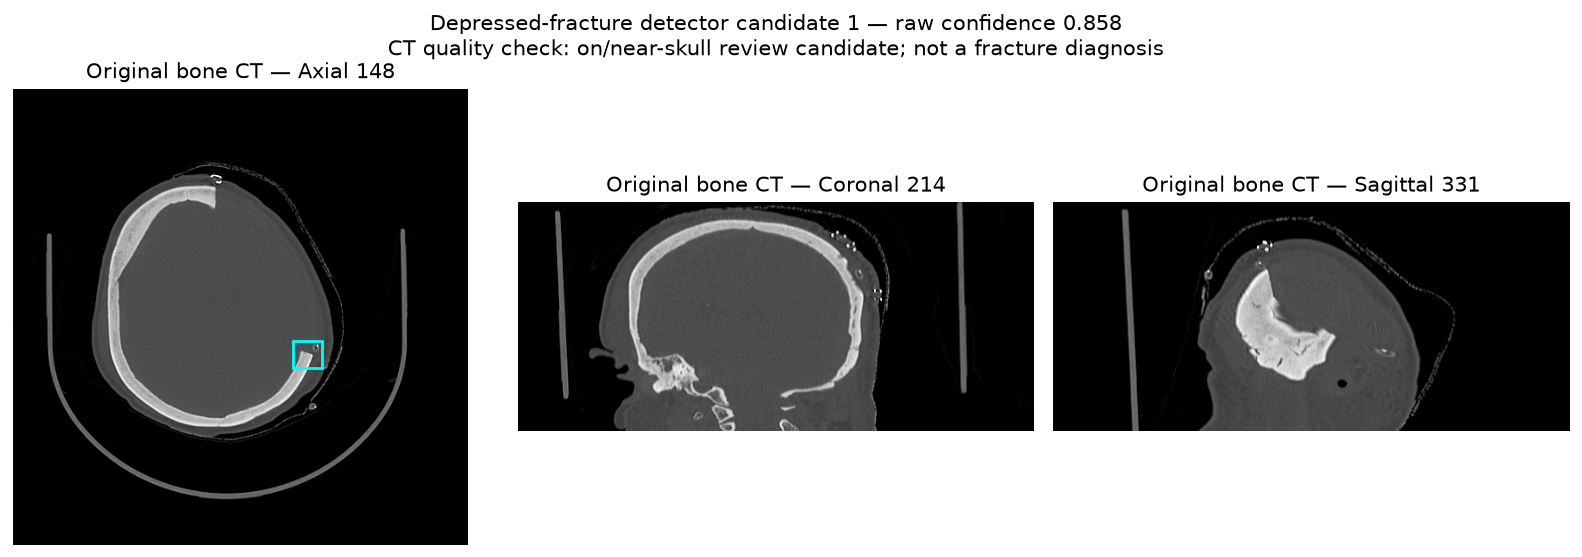

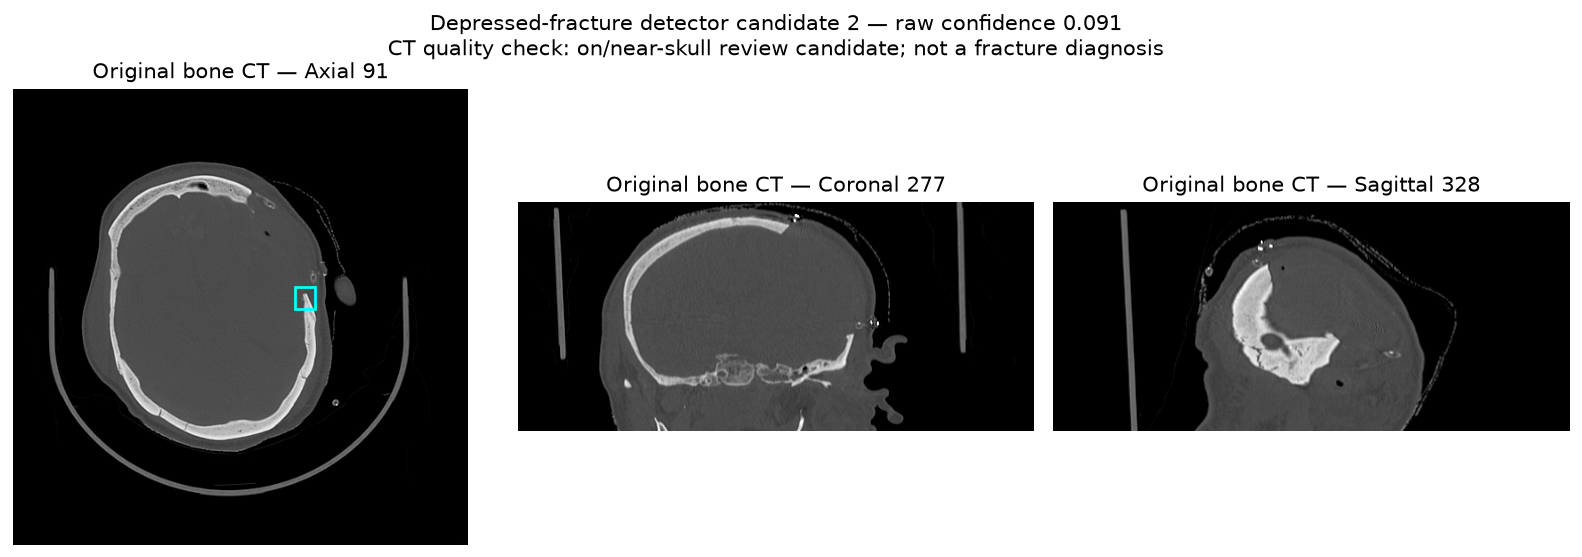

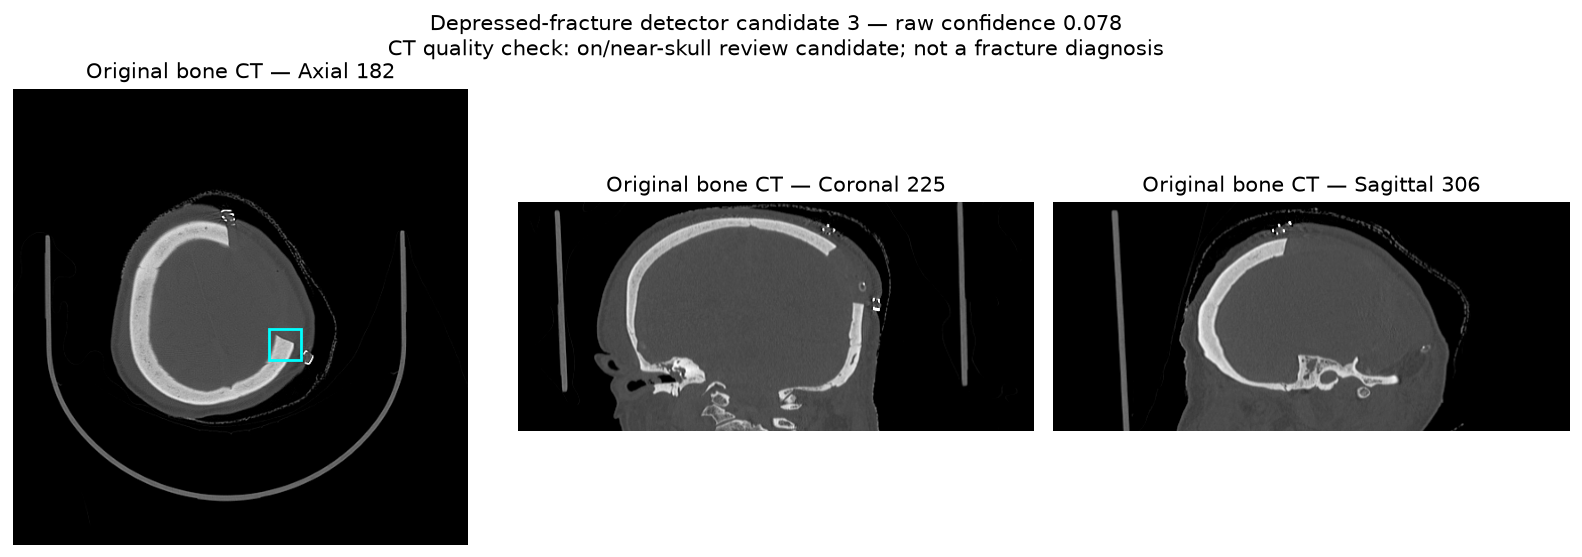

In [10]:
def show_fracture_candidate(row, rank):
    z = int(row.axial_slice)
    # Detector x is array column (voxel axis 1); detector y is array row (voxel axis 0).
    vox0 = int(round((row.y1 + row.y2)/2))
    vox1 = int(round((row.x1 + row.x2)/2))
    views = [
        (oriented_slice(bone_ct, 2, z), "Axial", z),
        (oriented_slice(bone_ct, 1, vox1), "Coronal", vox1),
        (oriented_slice(bone_ct, 0, vox0), "Sagittal", vox0),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
    for ax, (img, name, idx) in zip(axes, views):
        ax.imshow(img, cmap="gray", vmin=-800, vmax=2000)
        ax.set_title(f"Original bone CT — {name} {idx}")
        ax.axis("off")
    # Rectangle coordinates need the same 90-degree display transform.
    h, w = brain_ct.shape[:2]
    rect_x = row.y1
    rect_y = w - row.x2
    axes[0].add_patch(Rectangle((rect_x, rect_y), row.y2-row.y1, row.x2-row.x1,
                                fill=False, ec="cyan", lw=1.6))
    fig.suptitle(f"Depressed-fracture detector candidate {rank} — raw confidence {row.confidence_raw:.3f}\n"
                 f"CT quality check: {row.ct_quality_flag}; not a fracture diagnosis")
    fig.tight_layout()
    out = FIGURE_DIR / f"fracture_candidate_{rank:02d}_multiplanar.png"
    fig.savefig(out, bbox_inches="tight")
    plt.show()
    return out

fracture_figures = []
for rank, (_, cluster) in enumerate(fracture_clusters.head(3).iterrows(), start=1):
    row = fracture_df.loc[int(cluster.peak_detection_index)]
    fracture_figures.append(show_fracture_candidate(row, rank))
if fracture_df.empty:
    print("No detector boxes reached the low research-review threshold. This does not exclude a fracture.")

## 7. Geometric midline-shift prototype

This branch does not use a disease classifier. It estimates a skull/brain reference midline and the midpoint of bilateral central low-HU components on suitable axial slices. The measurement is exploratory because TotalSegmentator does not provide a dedicated septum-pellucidum or ventricle mask here. It should not replace a radiologist's standard landmark measurement.

In [11]:
lr_axis = next(i for i, c in enumerate(axcodes) if c in ("L", "R"))
if lr_axis != 0:
    print("LR axis is", lr_axis, "; this dataset is not in the expected voxel layout.")

world_coords = nib.affines.apply_affine(affine, np.argwhere(brain_mask))
reference_midline_x = float((world_coords[:, 0].min() + world_coords[:, 0].max()) / 2)

mls_rows = []
for z in brain_z:
    bm = brain_mask[:, :, z]
    if bm.sum() < 1000:
        continue
    d = inside_dist[:, :, z]
    low = bm & (d >= 8.0) & (brain_ct[:, :, z] >= -5) & (brain_ct[:, :, z] <= 30)
    lab, n = ndi.label(low, structure=np.ones((3,3), dtype=int))
    comps = []
    for cid in range(1, n+1):
        pts = np.argwhere(lab == cid)
        if len(pts) < 12:
            continue
        cvox = pts.mean(axis=0)
        cworld = nib.affines.apply_affine(affine, [cvox[0], cvox[1], z])
        comps.append((len(pts), cvox, cworld))
    left = [c for c in comps if c[2][0] < reference_midline_x and abs(c[2][0]-reference_midline_x) < 45]
    right = [c for c in comps if c[2][0] >= reference_midline_x and abs(c[2][0]-reference_midline_x) < 45]
    if not left or not right:
        continue
    lc = max(left, key=lambda q: q[0]); rc = max(right, key=lambda q: q[0])
    midpoint_x = float((lc[2][0] + rc[2][0]) / 2)
    mls_rows.append({
        "axial_slice": int(z), "reference_midline_world_x_mm": reference_midline_x,
        "candidate_midpoint_world_x_mm": midpoint_x,
        "signed_displacement_mm_RAS_x": midpoint_x-reference_midline_x,
        "absolute_displacement_mm": abs(midpoint_x-reference_midline_x),
        "left_component_voxels": lc[0], "right_component_voxels": rc[0],
        "method": "bilateral central low-HU component midpoint",
    })

mls_df = pd.DataFrame(mls_rows)
mls_df.to_csv(TABLE_DIR / "geometric_midline_shift_by_slice.csv", index=False)
if len(mls_df):
    robust_mls = float(mls_df.absolute_displacement_mm.median())
    q25, q75 = np.percentile(mls_df.absolute_displacement_mm, [25,75])
    print(f"Exploratory median displacement: {robust_mls:.2f} mm (IQR {q25:.2f}–{q75:.2f} mm), across {len(mls_df)} slices")
    display(mls_df.sort_values("absolute_displacement_mm", ascending=False).head(15).round(3))
else:
    robust_mls = np.nan
    print("Insufficient bilateral central low-HU components for a geometric estimate.")

Exploratory median displacement: 5.71 mm (IQR 2.71–9.03 mm), across 133 slices


,axial_slice,reference_midline_world_x_mm,candidate_midpoint_world_x_mm,signed_displacement_mm_RAS_x,absolute_displacement_mm,left_component_voxels,right_component_voxels,method
14,68,15.283,33.450,18.167,18.167,91,119,bilateral central low-HU component midpoint
15,69,15.283,31.548,16.265,16.265,116,65,bilateral central low-HU component midpoint
13,67,15.283,31.490,16.207,16.207,78,182,bilateral central low-HU component midpoint
11,65,15.283,31.426,16.143,16.143,49,95,bilateral central low-HU component midpoint
12,66,15.283,31.173,15.890,15.890,76,88,bilateral central low-HU component midpoint
16,70,15.283,30.244,14.960,14.960,113,56,bilateral central low-HU component midpoint
57,111,15.283,0.675,-14.608,14.608,675,1014,bilateral central low-HU component midpoint
45,99,15.283,1.984,-13.299,13.299,758,271,bilateral central low-HU component midpoint
117,171,15.283,2.104,-13.179,13.179,55,560,bilateral central low-HU component midpoint
118,172,15.283,2.268,-13.015,13.015,61,411,bilateral central low-HU component midpoint


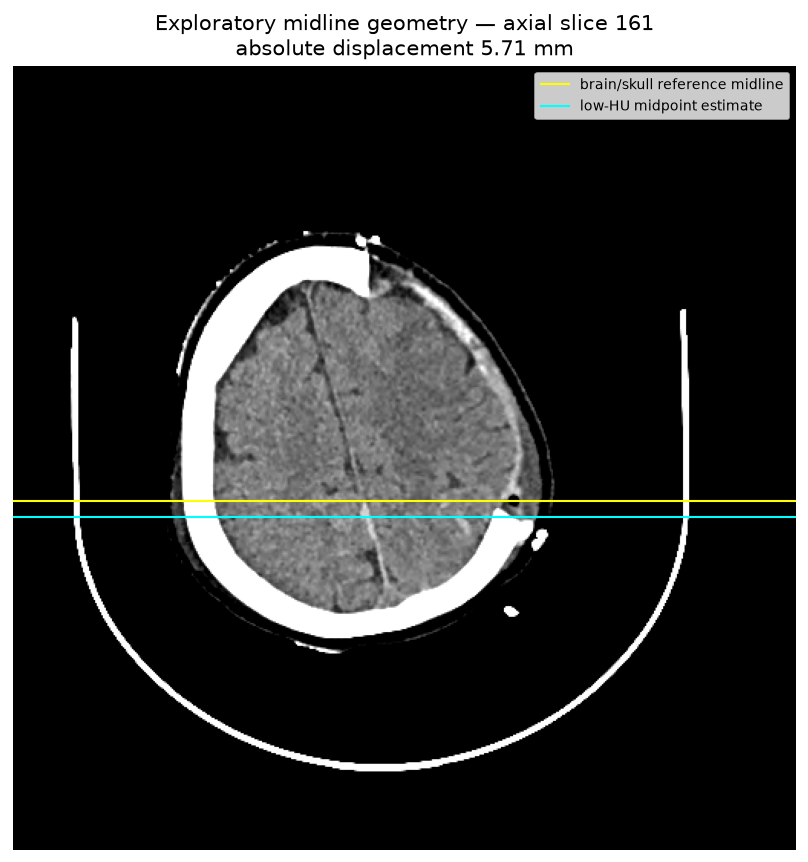

In [12]:
if len(mls_df):
    representative = mls_df.iloc[(mls_df.absolute_displacement_mm - robust_mls).abs().argmin()]
    z = int(representative.axial_slice)
    fig, ax = plt.subplots(figsize=(7,7))
    ax.imshow(np.rot90(brain_ct[:,:,z]), cmap="gray", vmin=0, vmax=80)
    # Convert voxel/world x lines to displayed y coordinates.
    inv_aff = np.linalg.inv(affine)
    ref_vox = nib.affines.apply_affine(inv_aff, [reference_midline_x, 0, 0])[0]
    cand_vox = nib.affines.apply_affine(inv_aff, [representative.candidate_midpoint_world_x_mm, 0, 0])[0]
    ax.axhline(brain_ct.shape[0]-ref_vox, color="yellow", lw=1.2, label="brain/skull reference midline")
    ax.axhline(brain_ct.shape[0]-cand_vox, color="cyan", lw=1.2, label="low-HU midpoint estimate")
    ax.set_title(f"Exploratory midline geometry — axial slice {z}\nabsolute displacement {representative.absolute_displacement_mm:.2f} mm")
    ax.legend(fontsize=8)
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "geometric_midline_shift_verification.png", bbox_inches="tight")
    plt.show()

## 8. Report-level comparison without treating the report as voxel ground truth

The mapping below asks whether a model has a compatible output class and shows the highest model score. It is **not** an accuracy table: there is only one patient, the report is not a voxel mask, some findings are only likely/suspected, and model scopes differ.

In [13]:
report_to_model = {
    "Hemorrhagic contusion": "intraparenchymal",
    "Acute subdural hematoma (SDH)": "subdural",
    "Posterior interhemispheric SDH": "subdural",
    "Intraventricular hemorrhage (IVH)": "intraventricular",
    "Subarachnoid hemorrhage (SAH)": "subarachnoid",
    "Mass effect / midline shift": "geometric_midline",
    "Postoperative extra-axial collection": None,
    "Right sphenoid bone fracture": "depressed_fracture_detector",
    "Right occipital bone fracture": "depressed_fracture_detector",
}

comparison_rows = []
for _, r in report_df.iterrows():
    model_target = report_to_model.get(r.finding)
    row = r.to_dict()
    row.update({"model_target": model_target, "score": np.nan, "uncertainty": np.nan,
                "best_axial_slice": np.nan, "spatial_match": np.nan,
                "comparison_note": "No compatible model output"})
    if model_target in ICH_CLASSES:
        j = ICH_CLASSES.index(model_target)
        z = int(np.argmax(mean_prob[:,j]))
        row.update({
            "score": float(mean_prob[z,j]), "uncertainty": float(sd_prob[z,j]),
            "best_axial_slice": z,
            "comparison_note": "Compatible subtype class only; this classifier does not verify report laterality/location",
        })
    elif model_target == "depressed_fracture_detector":
        if len(fracture_clusters):
            qa_supported = fracture_clusters[fracture_clusters.quality_flag_mode == "on/near-skull review candidate"]
            pool = qa_supported if len(qa_supported) else fracture_clusters
            right_clusters = pool[pool.hemisphere_by_RAS_x == "right"]
            top = (right_clusters.iloc[0] if len(right_clusters) else pool.iloc[0])
            side_match = bool(top.hemisphere_by_RAS_x == "right")
            location_note = ("right-sided candidate; exact named bone not established" if side_match else
                             f"top quality-screened candidate is {top.hemisphere_by_RAS_x}-sided, so it does not spatially support the right-sided report item")
            row.update({"score": float(top.peak_confidence_raw),
                        "uncertainty": float(top.adjacent_slice_confidence_sd) if pd.notna(top.adjacent_slice_confidence_sd) else np.nan,
                        "best_axial_slice": int(top.peak_axial_slice),
                        "spatial_match": side_match,
                        "comparison_note": f"Depressed-fracture cluster ({top.quality_flag_mode}); {location_note}"})
        else:
            row["comparison_note"] = "No low-threshold box; narrow detector cannot exclude reported fracture"
    elif model_target == "geometric_midline":
        row.update({"score": robust_mls, "comparison_note": "Score is displacement in mm, not probability"})
    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(TABLE_DIR / "report_model_comparison.csv", index=False)
display(comparison_df[["finding","report_status","region","model_target","score","uncertainty","best_axial_slice","comparison_note"]].round(4))

,finding,report_status,region,model_target,score,uncertainty,best_axial_slice,comparison_note
0,Hemorrhagic contusion,Reported,Left frontal and temporal lobes,intraparenchymal,0.0103,0.0144,95.0,Compatible subtype class only; this classifier...
1,Acute subdural hematoma (SDH),Reported,Left fronto-temporo-parietal region,subdural,0.2332,0.0871,109.0,Compatible subtype class only; this classifier...
2,Posterior interhemispheric SDH,Reported,Posterior interhemispheric region,subdural,0.2332,0.0871,109.0,Compatible subtype class only; this classifier...
3,Intraventricular hemorrhage (IVH),Likely,Bilateral lateral ventricular occipital horns,intraventricular,0.0079,0.0063,95.0,Compatible subtype class only; this classifier...
4,Subarachnoid hemorrhage (SAH),Likely,Left frontoparietal lobes,subarachnoid,0.0136,0.0018,202.0,Compatible subtype class only; this classifier...
5,Mass effect / midline shift,Reported,Midline; approximately 3 mm shift to the right,geometric_midline,5.7109,NaN,NaN,"Score is displacement in mm, not probability"
6,Postoperative extra-axial collection,Reported,Extra-axial postoperative region,NaN,NaN,NaN,NaN,No compatible model output
7,Right sphenoid bone fracture,Suspected,Right sphenoid bone,depressed_fracture_detector,0.8580,0.2931,148.0,Depressed-fracture cluster (on/near-skull revi...
8,Right occipital bone fracture,Suspected,Right occipital bone,depressed_fracture_detector,0.8580,0.2931,148.0,Depressed-fracture cluster (on/near-skull revi...


## 9. Quantitative prototype scorecard

There is no valid patient-level accuracy, sensitivity, specificity, Dice, or F1 calculation for these report findings because this case has no voxel-level lesion masks and only one report-level annotation set. Reporting such metrics would be misleading. The scorecard instead records model evidence, uncertainty, available 3-plane ranges, and method limitations.

In [14]:
scorecard = comparison_df.copy()
scorecard["calibration_status"] = "not locally calibrated; T=1.5 sensitivity and TTA spread available"
scorecard["original_ct_primary"] = True
scorecard["report_used_for_training"] = False
scorecard["report_is_voxel_ground_truth"] = False
scorecard.to_csv(TABLE_DIR / "multiview_neural_verification_scorecard.csv", index=False)

metrics = pd.DataFrame([
    {"branch":"hemorrhage CNN-LSTM", "model":"ResNet50 + bidirectional LSTM", "pretraining_target":"RSNA ICH subtypes",
     "outputs":len(ICH_CLASSES), "local_ground_truth_available":False, "valid_local_accuracy_metric":"not estimable"},
    {"branch":"skull fracture", "model":"YOLOv8 detector", "pretraining_target":"depressed skull fracture",
     "outputs":1, "local_ground_truth_available":False, "valid_local_accuracy_metric":"not estimable"},
    {"branch":"midline", "model":"geometric low-HU midpoint", "pretraining_target":"none",
     "outputs":1, "local_ground_truth_available":False, "valid_local_accuracy_metric":"not estimable"},
])
metrics.to_csv(TABLE_DIR / "method_metrics_and_validation_status.csv", index=False)
display(metrics)

,branch,model,pretraining_target,outputs,local_ground_truth_available,valid_local_accuracy_metric
0,hemorrhage CNN-LSTM,ResNet50 + bidirectional LSTM,RSNA ICH subtypes,6,False,not estimable
1,skull fracture,YOLOv8 detector,depressed skull fracture,1,False,not estimable
2,midline,geometric low-HU midpoint,none,1,False,not estimable


## 10. Final research summary and machine-readable export

In [15]:
case_summary = {
    "case": "CASE_001",
    "source_priority": "original CT is primary evidence",
    "orientation": list(axcodes),
    "spacing_mm": spacing.tolist(),
    "hemorrhage_model": {
        "architecture": "ResNet50 + 2-layer bidirectional LSTM",
        "training_source": "RSNA intracranial hemorrhage challenge",
        "classes": ICH_CLASSES,
        "checkpoint": str(ICH_WEIGHTS),
        "local_calibration": False,
        "uncertainty": "four fixed TTA views; SD and lower review score",
        "temperature_sensitivity": 1.5,
        "peak_scores": ich_summary.to_dict(orient="records"),
    },
    "fracture_model": {
        "architecture": "YOLOv8",
        "training_scope": "depressed skull fracture",
        "checkpoint": str(FRACTURE_WEIGHTS),
        "candidate_count_conf_ge_0_05": int(len(fracture_df)),
        "three_dimensional_candidate_clusters": int(len(fracture_clusters)),
        "cluster_scores": fracture_clusters.replace({np.nan: None}).to_dict(orient="records"),
        "local_calibration": False,
    },
    "midline_geometry": {
        "method": "bilateral central low-HU component midpoint relative to brain/skull reference",
        "median_absolute_displacement_mm": None if np.isnan(robust_mls) else robust_mls,
        "eligible_slices": int(len(mls_df)),
    },
    "report_comparison": comparison_df.replace({np.nan: None}).to_dict(orient="records"),
    "limitations": [
        "This is a single-case research prototype, not a clinical device.",
        "The report is report-level information, not voxel-level ground truth.",
        "Scores were not calibrated on a held-out cohort from this scanner/protocol.",
        "The hemorrhage network is a slice classifier and does not output lesion masks.",
        "The hybrid three-plane maps combine neural axial scores with native-HU/anatomical weighting.",
        "The fracture model targets depressed skull fracture and cannot exclude other fracture types.",
        "The midline measurement uses proxy low-HU anatomy rather than a dedicated clinical landmark model.",
        "Definitive interpretation requires expert radiological review.",
    ],
}
with open(OUTPUT_DIR / "CASE_001_multiview_neural_verification_summary.json", "w", encoding="utf-8") as f:
    json.dump(case_summary, f, indent=2)

print("Multi-view neural verification prototype completed.")
print("Hemorrhage classes:")
for _, r in ich_summary.iterrows():
    print(f"  {r['class']}: peak raw score {r['peak_raw_mean']:.3f} at axial slice {int(r['peak_native_slice'])}, TTA SD {r['TTA_SD_at_peak']:.3f}")
print("Fracture candidate boxes (research threshold 0.05):", len(fracture_df))
print("Fracture candidate clusters across neighbouring slices:", len(fracture_clusters))
print("Exploratory median midline displacement:", "unavailable" if np.isnan(robust_mls) else f"{robust_mls:.2f} mm")
print("All findings retain their report status; none is treated as voxel-level ground truth.")
print("Outputs saved to:", OUTPUT_DIR)

Multi-view neural verification prototype completed.
Hemorrhage classes:
  any: peak raw score 0.227 at axial slice 95, TTA SD 0.180
  intraparenchymal: peak raw score 0.010 at axial slice 95, TTA SD 0.014
  intraventricular: peak raw score 0.008 at axial slice 95, TTA SD 0.006
  subarachnoid: peak raw score 0.014 at axial slice 202, TTA SD 0.002
  subdural: peak raw score 0.233 at axial slice 109, TTA SD 0.087
  epidural: peak raw score 0.008 at axial slice 123, TTA SD 0.003
Fracture candidate boxes (research threshold 0.05): 58
Fracture candidate clusters across neighbouring slices: 4
Exploratory median midline displacement: 5.71 mm
All findings retain their report status; none is treated as voxel-level ground truth.
Outputs saved to: F:\csstdy\outputs\13_multiview_neural_verification


## Interpretation boundary

This notebook answers **where the models suggest reviewing** and **how stable the scores are**. It does not answer whether a disease is definitely present or absent. A radiologist must inspect the original brain and bone reconstructions across contiguous slices and apply clinical criteria.